In [493]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [494]:
import sys
import os

sys.path.append(os.path.abspath(".."))

from src.load_master_data import load_master_data

df = load_master_data()

df.head()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25939 entries, 0 to 25938
Data columns (total 39 columns):
 #   Column                             Non-Null Count  Dtype         
---  ------                             --------------  -----         
 0   season                             25939 non-null  int64         
 1   round                              25939 non-null  int64         
 2   driver_id                          25939 non-null  category      
 3   driver_name                        25939 non-null  category      
 4   constructor_id                     25939 non-null  category      
 5   grid                               25939 non-null  int64         
 6   position                           25939 non-null  int64         
 7   points                             25939 non-null  float64       
 8   laps                               25939 non-null  int64         
 9   status                             25939 non-null  category      
 10  time                               8354 non-n

In [495]:
target = "podium"

df[target].value_counts()

df[target].value_counts(normalize=True)

podium
0    0.865916
1    0.134084
Name: proportion, dtype: float64

In [496]:
features = [
    "grid",
    "qualifying_position",
    "driver_age",
    "pole_position",
    "front_row",
    "constructor_name",
    "driver_nationality",
    "circuit_country",
    "current_season_points",
    "avg_points_per_season",
    "constructor_points_current_season",
    "points_last_5_races"
]

descriminative_numerical_features = []
descriminative_categorical_features = []

In [497]:
X = df[features]

y = df[target]

In [498]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 25939 entries, 0 to 25938
Data columns (total 12 columns):
 #   Column                             Non-Null Count  Dtype   
---  ------                             --------------  -----   
 0   grid                               25939 non-null  int64   
 1   qualifying_position                11029 non-null  float64 
 2   driver_age                         25939 non-null  float64 
 3   pole_position                      25939 non-null  int64   
 4   front_row                          25939 non-null  int64   
 5   constructor_name                   25939 non-null  category
 6   driver_nationality                 25939 non-null  category
 7   circuit_country                    25939 non-null  category
 8   current_season_points              25939 non-null  float64 
 9   avg_points_per_season              22289 non-null  float64 
 10  constructor_points_current_season  25939 non-null  float64 
 11  points_last_5_races                25121 non-null  f

## GRID T TEST

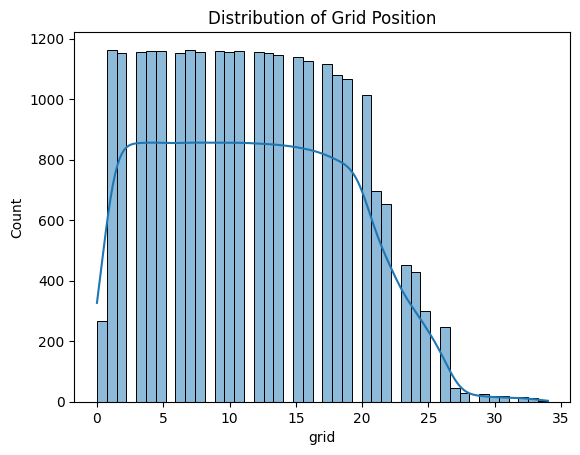

In [499]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(df["grid"], kde=True)

plt.title("Distribution of Grid Position")

plt.show()

In [500]:
from scipy.stats import mannwhitneyu

# Separate groups
podium_group = df[
    df["podium"] == 1
]["grid"]

non_podium_group = df[
    df["podium"] == 0
]["grid"]

# Mann-Whitney U test
u_stat, p_value = mannwhitneyu(
    podium_group,
    non_podium_group,
    alternative="two-sided"
)

print("U-statistic:", u_stat)
print("P-value:", p_value)

U-statistic: 9878160.5
P-value: 0.0


In [501]:
alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("The variable 'grid' is discriminative.")
    descriminative_numerical_features.append("grid")
else:
    print("Fail to reject H0")
    print("The variable 'grid' is class independent.")

Reject H0
The variable 'grid' is discriminative.


### Hypothesis Test for Grid Position

H0: The variable 'grid' is class independent.

H1: The variable 'grid' is not class independent.

Confidence level = 95%
α = 0.05

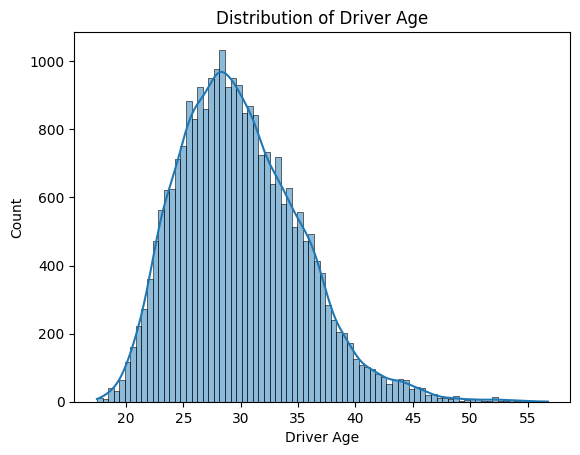

In [502]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(
    df["driver_age"],
    kde=True
)

plt.title("Distribution of Driver Age")

plt.xlabel("Driver Age")

plt.ylabel("Count")

plt.show()

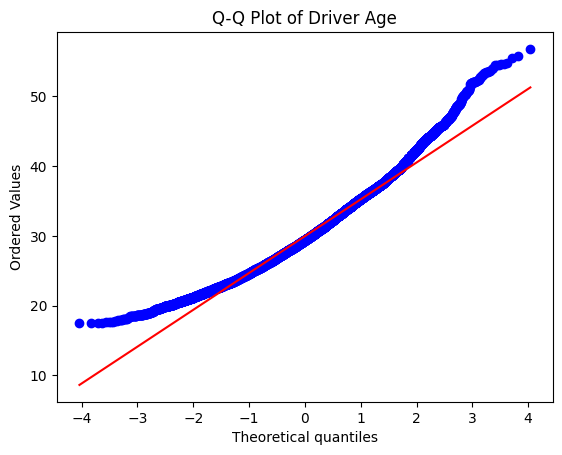

In [503]:
import scipy.stats as stats
import matplotlib.pyplot as plt

stats.probplot(
    df["driver_age"],
    dist="norm",
    plot=plt
)

plt.title("Q-Q Plot of Driver Age")

plt.show()

In [504]:
from scipy.stats import mannwhitneyu


# Separate groups
podium_group = df[
    df["podium"] == 1
]["driver_age"]

non_podium_group = df[
    df["podium"] == 0
]["driver_age"]

# T-test
t_stat, p_value = mannwhitneyu(
    podium_group,
    non_podium_group,
    nan_policy="omit"
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: 42559063.5
P-value: 1.656553146433306e-17


In [505]:
alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("The variable 'driver_age' is discriminative.")
    descriminative_numerical_features.append("driver_age")
else:
    print("Fail to reject H0")
    print("The variable 'driver_age' is class independent.")

Reject H0
The variable 'driver_age' is discriminative.


In [506]:
from scipy.stats import chi2_contingency

# Create contingency table
contingency_table = pd.crosstab(
    df["front_row"],
    df["podium"]
)

# Perform Chi-square test
chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)

Chi-square statistic: 4045.2462825884727
P-value: 0.0


In [507]:
alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("Front row starts are associated with podium finishes.")
    descriminative_categorical_features.append("front_row")
else:
    print("Fail to reject H0")
    print("Front row starts are independent of podium finishes.")

Reject H0
Front row starts are associated with podium finishes.


In [508]:
from scipy.stats import chi2_contingency

# Contingency table
contingency_table = pd.crosstab(
    df["constructor_name"],
    df["podium"]
)

# Chi-square test
chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)

Chi-square statistic: 3711.3602882742834
P-value: 0.0


In [509]:
alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("Constructor name is associated with podium finishes.")
    descriminative_categorical_features.append("constructor_name")
else:
    print("Fail to reject H0")
    print("Constructor name is independent of podium finishes.")

Reject H0
Constructor name is associated with podium finishes.


In [510]:
# Contingency table
contingency_table = pd.crosstab(
    df["circuit_country"],
    df["podium"]
)

# Chi-square test
chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)

df.info()

Chi-square statistic: 9.27955285158374
P-value: 0.999984847062557
<class 'pandas.DataFrame'>
RangeIndex: 25939 entries, 0 to 25938
Data columns (total 39 columns):
 #   Column                             Non-Null Count  Dtype         
---  ------                             --------------  -----         
 0   season                             25939 non-null  int64         
 1   round                              25939 non-null  int64         
 2   driver_id                          25939 non-null  category      
 3   driver_name                        25939 non-null  category      
 4   constructor_id                     25939 non-null  category      
 5   grid                               25939 non-null  int64         
 6   position                           25939 non-null  int64         
 7   points                             25939 non-null  float64       
 8   laps                               25939 non-null  int64         
 9   status                             25939 non-null 

In [511]:
# Contingency table
contingency_table = pd.crosstab(
    df["driver_nationality"],
    df["podium"]
)

# Chi-square test
chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)

Chi-square statistic: 795.4696292875008
P-value: 8.634066317202463e-142


In [512]:
alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("Driver nationality is associated with podium finishes.")
    descriminative_categorical_features.append("driver_nationality")
else:
    print("Fail to reject H0")
    print("Driver nationality is independent of podium finishes.")

Reject H0
Driver nationality is associated with podium finishes.


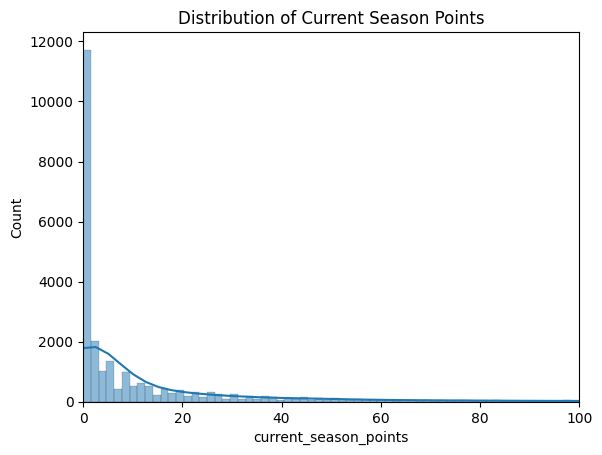

In [513]:
sns.histplot(
    df["current_season_points"],
    kde=True
)

plt.title("Distribution of Current Season Points")

plt.xlim(0,100)

plt.show()

In [514]:
from scipy.stats import mannwhitneyu

# Separate groups
podium_group = df[
    df["podium"] == 1
]["current_season_points"]

non_podium_group = df[
    df["podium"] == 0
]["current_season_points"]

# Mann-Whitney U test
u_stat, p_value = mannwhitneyu(
    podium_group,
    non_podium_group,
    alternative="two-sided"
)

print("U-statistic:", u_stat)
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("Current season points is discriminative.")
    descriminative_numerical_features.append("current_season_points")
else:
    print("Fail to reject H0")
    print("Current season points is class independent.")

U-statistic: 58953609.0
P-value: 0.0
Reject H0
Current season points is discriminative.


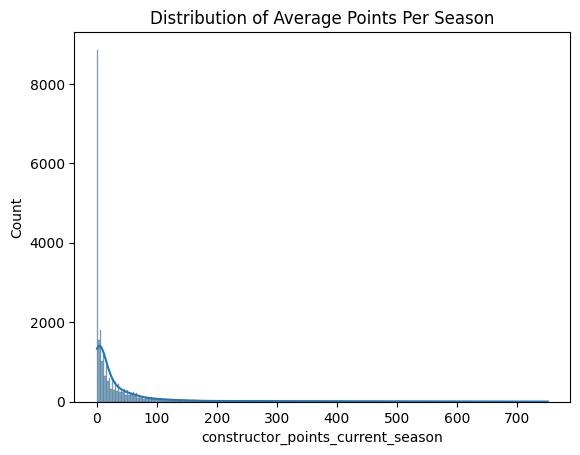

In [515]:
sns.histplot(
    df["constructor_points_current_season"],
    kde=True
)

plt.title("Distribution of Average Points Per Season")

plt.show()



In [516]:
# Separate groups and remove NaNs

podium_group = df[
    df["podium"] == 1
]["constructor_points_current_season"]

non_podium_group = df[
    df["podium"] == 0
]["constructor_points_current_season"]

# Mann-Whitney U test

u_stat, p_value = mannwhitneyu(
    podium_group,
    non_podium_group,
    alternative="two-sided"
)

print("U-statistic:", u_stat)
print("P-value:", p_value)

U-statistic: 58249338.5
P-value: 0.0


In [517]:
alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("Constructor points is discriminative.")
    descriminative_numerical_features.append("constructor_points_current_season")
else:
    print("Fail to reject H0")
    print("Constructor points is class independent.")

Reject H0
Constructor points is discriminative.


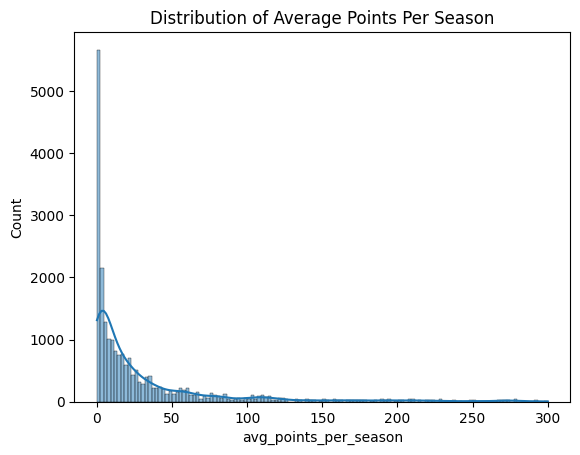

In [518]:
sns.histplot(
    df["avg_points_per_season"],
    kde=True
)

plt.title("Distribution of Average Points Per Season")

plt.show()

In [519]:
# Separate groups and remove NaNs

podium_group = df[
    df["podium"] == 1
]["avg_points_per_season"]

non_podium_group = df[
    df["podium"] == 0
]["avg_points_per_season"]
# Mann-Whitney U test

u_stat, p_value = mannwhitneyu(
    podium_group,
    non_podium_group,
    alternative="two-sided"
)

print("U-statistic:", u_stat)
print("P-value:", p_value)

U-statistic: nan
P-value: nan


In [520]:
alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("Average points per season is discriminative.")
    descriminative_numerical_features.append("avg_points_per_season")
else:
    print("Fail to reject H0")
    print("Average points per season is class independent.")

Fail to reject H0
Average points per season is class independent.


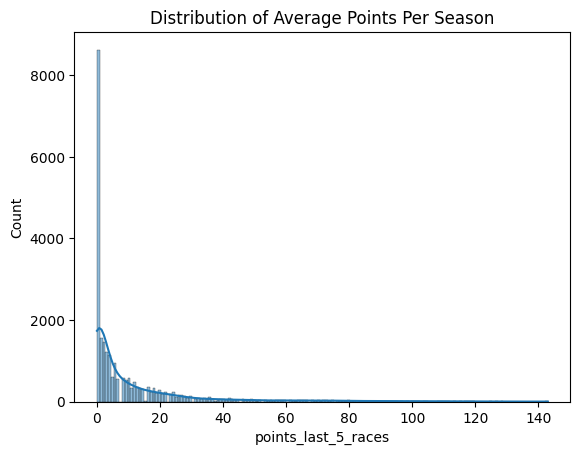

In [521]:
sns.histplot(
    df["points_last_5_races"],
    kde=True
)

plt.title("Distribution of Average Points Per Season")

plt.show()

In [522]:
# Separate groups and remove NaNs

podium_group = df[
    df["podium"] == 1
]["points_last_5_races"]

non_podium_group = df[
    df["podium"] == 0
]["points_last_5_races"]

# Mann-Whitney U test

u_stat, p_value = mannwhitneyu(
    podium_group,
    non_podium_group,
    alternative="two-sided"
)

print("U-statistic:", u_stat)
print("P-value:", p_value)

U-statistic: nan
P-value: nan


In [523]:
alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("points_last_5_races is discriminative.")
    descriminative_numerical_features.append("points_last_5_races")

else:
    print("Fail to reject H0")
    print("points_last_5_races is class independent.")

Fail to reject H0
points_last_5_races is class independent.


In [524]:
correlation_matrix = (
    df[descriminative_numerical_features]
    .corr()
)

correlation_matrix

,grid,driver_age,current_season_points,constructor_points_current_season
grid,1.000000,-0.057301,-0.350153,-0.342130
driver_age,-0.057301,1.000000,-0.029959,-0.015882
current_season_points,-0.350153,-0.029959,1.000000,0.954218
constructor_points_current_season,-0.342130,-0.015882,0.954218,1.000000


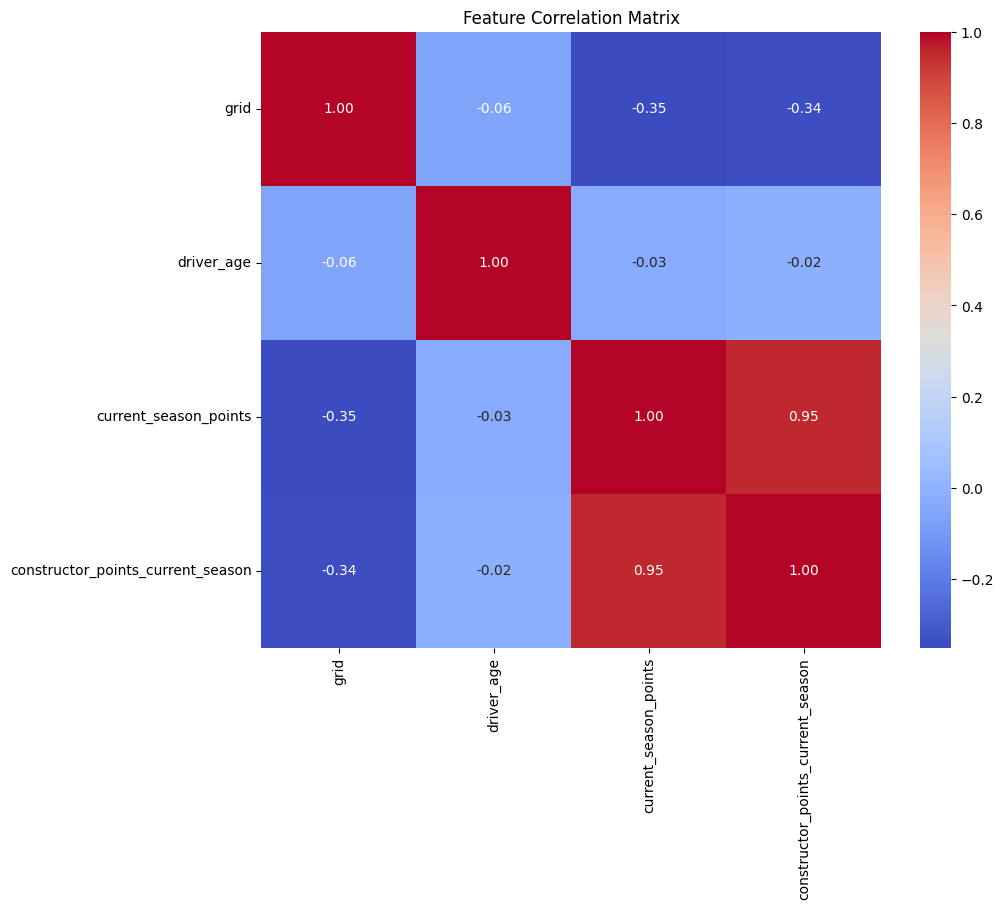

In [525]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Matrix")

plt.show()

In [526]:
corr_matrix = (
    df[descriminative_numerical_features]
    .corr()
    .abs()
)

# Upper triangle only
upper_triangle = corr_matrix.where(
    np.triu(
        np.ones(corr_matrix.shape),
        k=1
    ).astype(bool)
)

# Find features with correlation > 0.9
high_corr_features = [
    column
    for column in upper_triangle.columns
    if any(upper_triangle[column] > 0.9)
]

print(high_corr_features)

['constructor_points_current_season']


In [527]:
from scipy.stats import chi2_contingency
import numpy as np

def cramers_v(x, y):

    contingency_table = pd.crosstab(x, y)

    chi2 = chi2_contingency(contingency_table)[0]

    n = contingency_table.sum().sum()

    r, k = contingency_table.shape

    return np.sqrt(
        chi2 / (n * (min(r, k) - 1))
    )

In [528]:
cramers_matrix = pd.DataFrame(
    index=descriminative_categorical_features,
    columns=descriminative_categorical_features
)

for col1 in descriminative_categorical_features:
    for col2 in descriminative_categorical_features:

        cramers_matrix.loc[col1, col2] = (
            cramers_v(
                df[col1],
                df[col2]
            )
        )

cramers_matrix

,front_row,constructor_name,driver_nationality
front_row,0.999785,0.323896,0.157325
constructor_name,0.323896,1.0,0.369019
driver_nationality,0.157325,0.369019,1.0


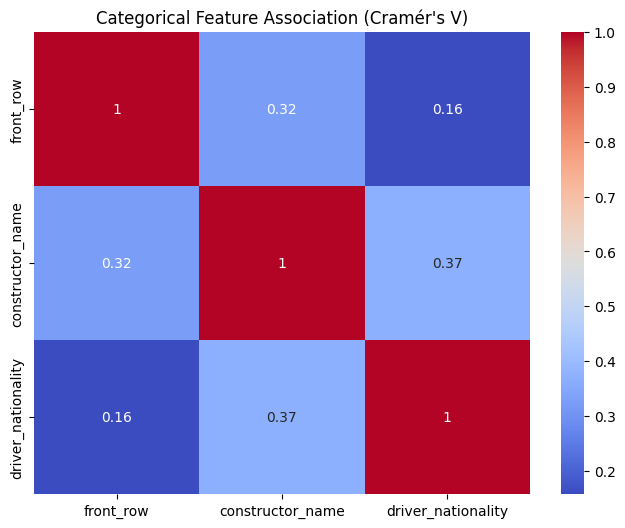

In [529]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    cramers_matrix.astype(float),
    annot=True,
    cmap="coolwarm"
)

plt.title("Categorical Feature Association (Cramér's V)")

plt.show()

In [530]:
final_features = (
    descriminative_numerical_features +
    descriminative_categorical_features
)

final_features

['grid',
 'driver_age',
 'current_season_points',
 'constructor_points_current_season',
 'front_row',
 'constructor_name',
 'driver_nationality']

In [531]:
X = df[final_features]

y = df["podium"]

In [532]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [533]:
X_train = pd.get_dummies(
    X_train,
    drop_first=True
)

X_test = pd.get_dummies(
    X_test,
    drop_first=True
)

# Align columns
X_train, X_test = X_train.align(
    X_test,
    join="left",
    axis=1,
    fill_value=0
)

In [534]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train
)

X_test_scaled = scaler.transform(
    X_test
)

In [535]:
df["avg_points_per_season"] = (
    df["avg_points_per_season"]
    .fillna(0)
)

df["current_season_points"] = (
    df["current_season_points"]
    .fillna(0)
)

df["points_last_5_races"] = (
    df["points_last_5_races"]
    .fillna(0)
)

In [536]:
X.isna().sum()

grid                                 0
driver_age                           0
current_season_points                0
constructor_points_current_season    0
front_row                            0
constructor_name                     0
driver_nationality                   0
dtype: int64

In [537]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

model.fit(
    X_train_scaled,
    y_train
)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :ter

In [538]:
y_pred = model.predict(
    X_test_scaled
)

In [539]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print(
    "Accuracy:",
    accuracy_score(y_test, y_pred)
)

print(
    classification_report(y_test, y_pred)
)

print(
    confusion_matrix(y_test, y_pred)
)

Accuracy: 0.7827679259830378
              precision    recall  f1-score   support

           0       0.97      0.77      0.86      4492
           1       0.37      0.87      0.52       696

    accuracy                           0.78      5188
   macro avg       0.67      0.82      0.69      5188
weighted avg       0.89      0.78      0.81      5188

[[3455 1037]
 [  90  606]]


In [540]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(
    X_train,
    y_train
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y

In [541]:
y_pred_rf = rf_model.predict(X_test)

In [542]:
print(
    classification_report(
        y_test,
        y_pred_rf
    )
)

print(
    confusion_matrix(
        y_test,
        y_pred_rf
    )
)

              precision    recall  f1-score   support

           0       0.96      0.83      0.89      4492
           1       0.41      0.76      0.54       696

    accuracy                           0.82      5188
   macro avg       0.69      0.80      0.71      5188
weighted avg       0.88      0.82      0.84      5188

[[3737  755]
 [ 165  531]]


In [543]:
feature_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="importance",
    ascending=False
)

feature_importance

,feature,importance
0,grid,0.329162
3,constructor_points_current_season,0.143560
2,current_season_points,0.138013
4,front_row,0.133959
75,constructor_name_Ferrari,0.046056
...,...,...
199,constructor_name_Turner,0.000000
190,constructor_name_Tec-Mec,0.000000
187,constructor_name_Sutton,0.000000
228,driver_nationality_Indonesian,0.000000


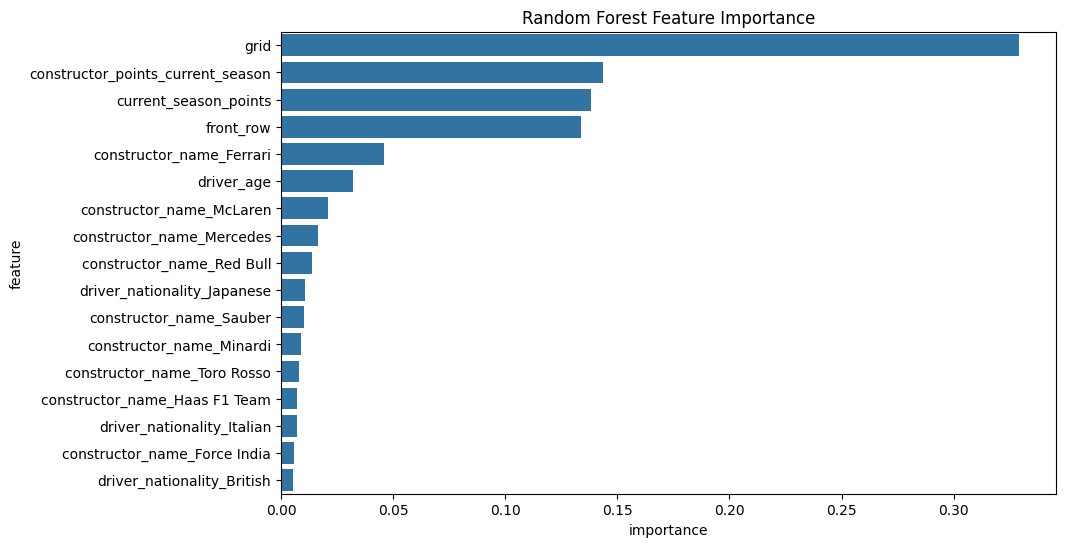

In [544]:
important_features = feature_importance[
    feature_importance["importance"] > 0.005
]

plt.figure(figsize=(10, 6))

sns.barplot(
    data=important_features,
    x="importance",
    y="feature"
)

plt.title("Random Forest Feature Importance")

plt.show()

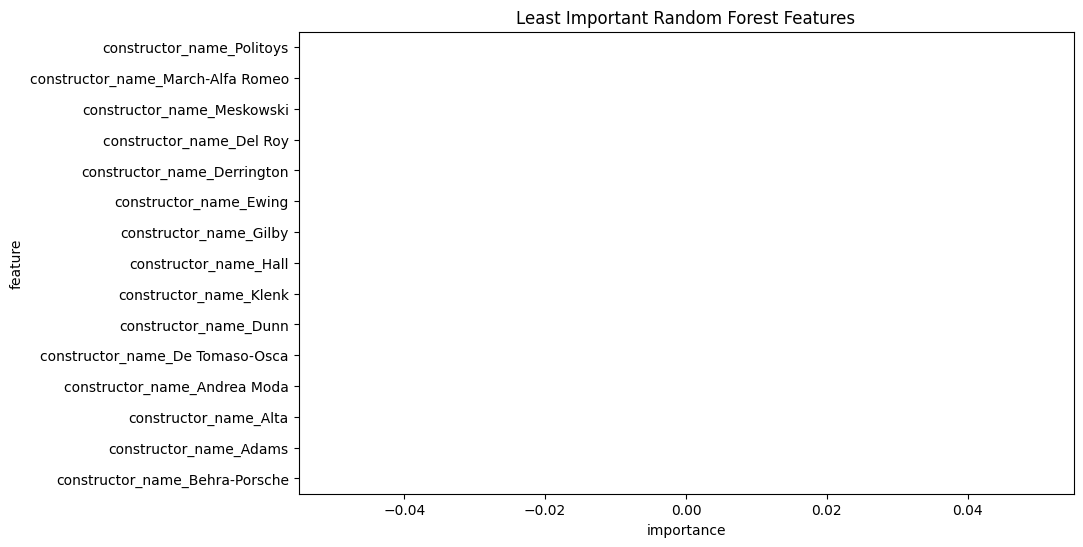

In [545]:
# Least important features

least_important = (
    feature_importance
    .sort_values(by="importance", ascending=True)
    .head(15)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=least_important,
    x="importance",
    y="feature"
)

plt.title("Least Important Random Forest Features")

plt.show()

In [546]:
# Chronological train-test split

train_df = df[
    df["season"] <= 2014
]

test_df = df[
    df["season"] > 2014
]

# Features and target

X_train = train_df[features]
y_train = train_df["podium"]

X_test = test_df[features]
y_test = test_df["podium"]

# Fill missing values

X_train = X_train.fillna(0)
X_test = X_test.fillna(0)

# One-hot encoding

X_train = pd.get_dummies(
    X_train,
    drop_first=True
)

X_test = pd.get_dummies(
    X_test,
    drop_first=True
)

# Align columns

X_train, X_test = X_train.align(
    X_test,
    join="left",
    axis=1,
    fill_value=0
)

# Scale features

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train
)

X_test_scaled = scaler.transform(
    X_test
)

In [547]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(
    X_train,
    y_train
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y

In [598]:
y_prob = rf_model.predict_proba(X_test)[:, 1]

y_pred_custom = (
    y_prob > 0.7
).astype(int)

In [599]:
print(
    classification_report(
        y_test,
        y_pred_custom
    )
)

print(
    confusion_matrix(
        y_test,
        y_pred_custom
    )
)

              precision    recall  f1-score   support

           0       0.96      0.89      0.93      4056
           1       0.57      0.80      0.66       708

    accuracy                           0.88      4764
   macro avg       0.77      0.85      0.80      4764
weighted avg       0.90      0.88      0.89      4764

[[3629  427]
 [ 144  564]]


In [550]:
feature_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="importance",
    ascending=False
)

feature_importance

,feature,importance
0,grid,0.221997
8,points_last_5_races,0.155253
6,avg_points_per_season,0.110180
5,current_season_points,0.102259
7,constructor_points_current_season,0.077451
...,...,...
226,driver_nationality_East German,0.000000
236,driver_nationality_Liechtensteiner,0.000000
232,driver_nationality_Indonesian,0.000000
42,constructor_name_Cadillac F1 Team,0.000000


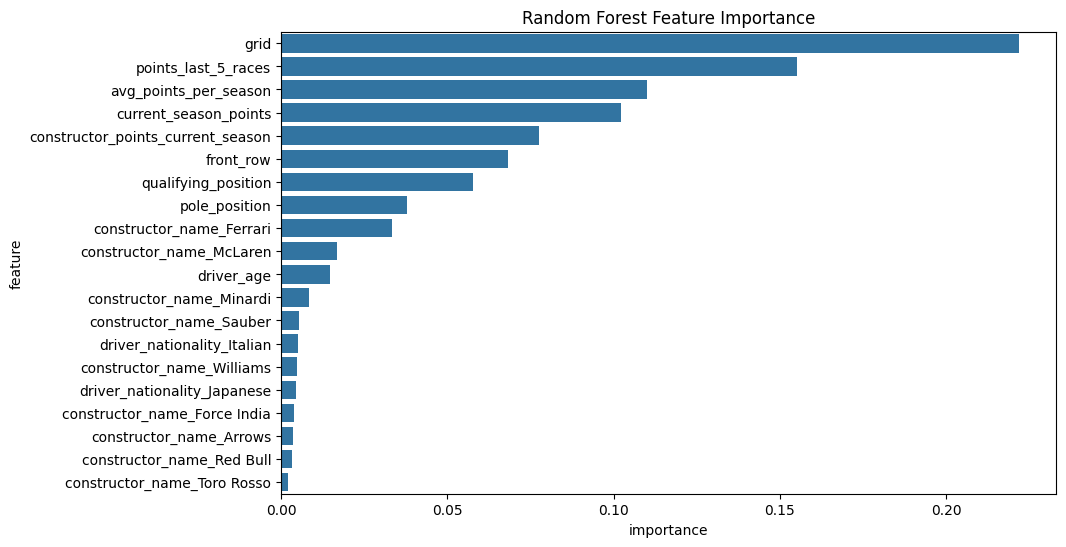

In [551]:
important_features = feature_importance[
    feature_importance["importance"] > 0.002
]

plt.figure(figsize=(10, 6))

sns.barplot(
    data=important_features,
    x="importance",
    y="feature"
)

plt.title("Random Forest Feature Importance")

plt.show()